# Exploration Q7 & Q8 : Typologie des stations et politique de rééquilibrage

Ce notebook présente l'exploration des données nettoyées de CityCycle afin d'identifier des profils de stations et d'en déduire une politique de rééquilibrage adaptée.

In [9]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# import des modules depuis /src
sys.path.append(str(Path("../src").resolve()))

from data_loader import get_prepared_dataset
from features import flux_station_heure, profil_stations

## 1. Chargement et exploration des variables

### Choix des colonnes et lecture des résultats

* **Colonnes retenues pour K-Means (`capacite`, `altitude_m`, `interventions_mois`) :** elles couvrent trois dimensions complémentaires (taille de la station, relief, charge terrain) avec peu de corrélation entre elles, et elles sont standardisées (`StandardScaler`) avant le clustering.
* **Colonnes gardées hors du clustering :** `station_id` est un identifiant, `longitude_km`/`latitude_km` évitent un découpage purement géographique, et `type_quartier` ainsi que les variables de flux (`dep_matin`, `arr_matin`, `solde_matin`) servent à analyser et vérifier les groupes après coup.


Corrélation de 'longitude_km' avec les autres variables


,corr_longitude_km
longitude_km,1.00
latitude_km,0.12
capacite,0.09
altitude_m,0.04
interventions_mois,0.16



Corrélation de 'latitude_km' avec les autres variables


,corr_latitude_km
longitude_km,0.12
latitude_km,1.00
capacite,-0.04
altitude_m,-0.13
interventions_mois,0.01



Corrélation de 'capacite' avec les autres variables


,corr_capacite
longitude_km,0.09
latitude_km,-0.04
capacite,1.00
altitude_m,-0.12
interventions_mois,-0.13



Corrélation de 'altitude_m' avec les autres variables


,corr_altitude_m
longitude_km,0.04
latitude_km,-0.13
capacite,-0.12
altitude_m,1.00
interventions_mois,-0.04



Corrélation de 'interventions_mois' avec les autres variables


,corr_interventions_mois
longitude_km,0.16
latitude_km,0.01
capacite,-0.13
altitude_m,-0.04
interventions_mois,1.00


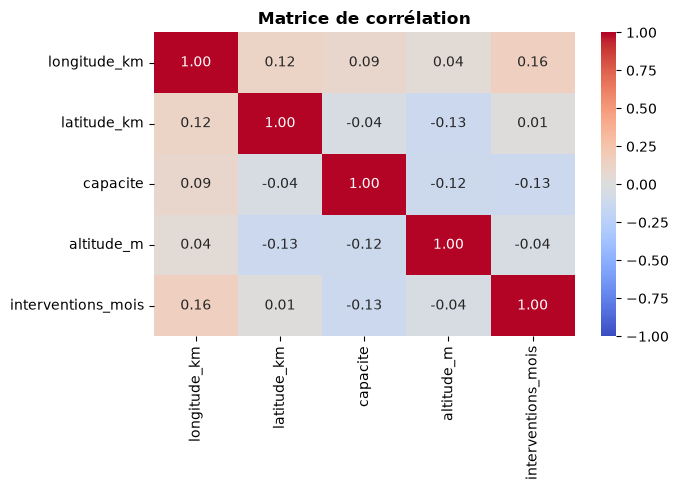

In [31]:
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

from data_loader import get_prepared_dataset
from features import flux_station_heure, profil_stations

df_stations, df_trajets, _ = get_prepared_dataset()
flux = flux_station_heure(df_trajets, df_stations)
df_profil = profil_stations(flux, df_stations)

#Corrélations sur toutes les variables numériques (hors cluster)
cols_num = (
    df_stations.select_dtypes(include="number")
    .drop(columns=["cluster"], errors="ignore")
    .columns
)
corr = df_stations[cols_num].corr().round(2)

# Affichage d'un petit tableau de corrélation par variable
for col in cols_num:
  print(f"\nCorrélation de '{col}' avec les autres variables")
  tableau = corr[[col]].rename(columns={col: f"corr_{col}"})
  display(tableau)

# Matrice visuelle globale
plt.figure(figsize=(7, 5))
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1
)
plt.title(
    "Matrice de corrélation",
    fontsize=12,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

L'analyse des corrélations montre que les coefficients entre les variables numériques du fichier sont tous très faibles (compris entre **-0,13** et **+0,16**).

En particulier, les trois variables retenues pour le clustering — **`capacite`**, **`altitude_m`** et **`interventions_mois`** — présentent des corrélations très faibles entre elles (**-0,12**, **-0,13** et **-0,04**) :
- **Absence de redondance :** elles ne font pas doublon et apportent chacune une information distincte (taille physique de la station, dénivelé et charge d'interventions sur le terrain).
- **Exclusion des coordonnées GPS (`longitude_km`, `latitude_km`) :** l'objectif étant de regrouper les stations selon leur comportement d'exploitation et non selon leur position géographique, ces deux variables sont écartées de l'algorithme K-Means.

In [10]:
df_stations, df_trajets, _ = get_prepared_dataset()
flux = flux_station_heure(df_trajets, df_stations)
df_profil = profil_stations(flux, df_stations)

cols = ["capacite", "altitude_m", "interventions_mois"]
display(df_stations[cols].describe().round(2))

,capacite,altitude_m,interventions_mois
count,140.00,140.00,140.00
mean,21.87,54.64,5.09
std,7.06,21.53,3.50
min,8.00,25.00,0.00
25%,17.00,37.00,3.00
50%,21.00,51.00,4.00
75%,27.00,70.00,6.00
max,44.00,109.00,20.00


### Analyse descriptive des variables retenues (`describe`)

Le résumé statistique des 140 stations sur les trois variables retenues (`capacite`, `altitude_m` et `interventions_mois`) permet de valider la qualité et la structure des données avant le clustering :

- **Complétude des données (`count = 140`) :** aucune valeur manquante n'est présente sur les trois variables.
- **Échelles et dispersions hétérogènes (`mean` et `std`) :** les grandeurs diffèrent nettement d'une colonne à l'autre — en moyenne **21,87 bornes** (écart-type de **7,06**), **54,64 m d'altitude** (écart-type de **21,53**) et **5,09 interventions/mois** (écart-type de **3,50**). Cette différence d'échelle justifie la **standardisation (`StandardScaler`)** avant l'application de K-Means afin qu'aucune variable ne domine le calcul des distances.
- **Présence de profils contrastés (`min`, médiane `50%`, `max`) :**
  - `capacite` s'étend de **8** à **44 bornes** (médiane à **21**).
  - `altitude_m` varie de **25 m** à **109 m** (médiane à **51 m**), traduisant un dénivelé marqué entre plaine et hauteurs.
  - `interventions_mois` va de **0** à **20 interventions/mois** (médiane à **4** ; 75 % des stations ont **6 interventions ou moins**), ce qui met en évidence un sous-groupe de stations très sollicitées.

## 2. Choix du nombre de clusters $k$ (Inertie et Silhouette)

,k,inertie,silhouette
0,2,304.4,0.29
1,3,223.5,0.31
2,4,172.1,0.30
3,5,144.0,0.29


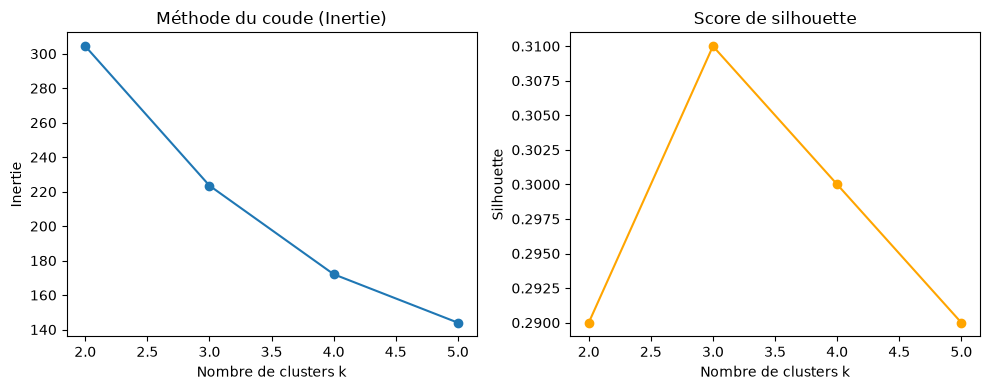

In [11]:
X = StandardScaler().fit_transform(df_stations[cols])

resultats_k = []

for k in range(2, 6):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    resultats_k.append({
        "k": k,
        "inertie": round(km.inertia_, 1),
        "silhouette": round(silhouette_score(X, labels), 2),
    })

df_k = pd.DataFrame(resultats_k)
display(df_k)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(df_k["k"], df_k["inertie"], marker="o")
ax[0].set_title("Méthode du coude (Inertie)")
ax[0].set_xlabel("Nombre de clusters k")
ax[0].set_ylabel("Inertie")

ax[1].plot(df_k["k"], df_k["silhouette"], marker="o", color="orange")
ax[1].set_title("Score de silhouette")
ax[1].set_xlabel("Nombre de clusters k")
ax[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

**Choix retenu : $k = 3$**
- Pour $k = 3$, les stations sont bien regroupées autour du centre (baisse nette de l'inertie) et le score de silhouette atteint son maximum ($0{,}31$) parmi les valeurs testées.
- Sur le plan métier, 3 profils distinguent clairement les stations calmes, les grandes stations régulières et le groupe critique des gares.

## 3. Profil des 3 clusters et croisement avec les quartiers (Question 7)

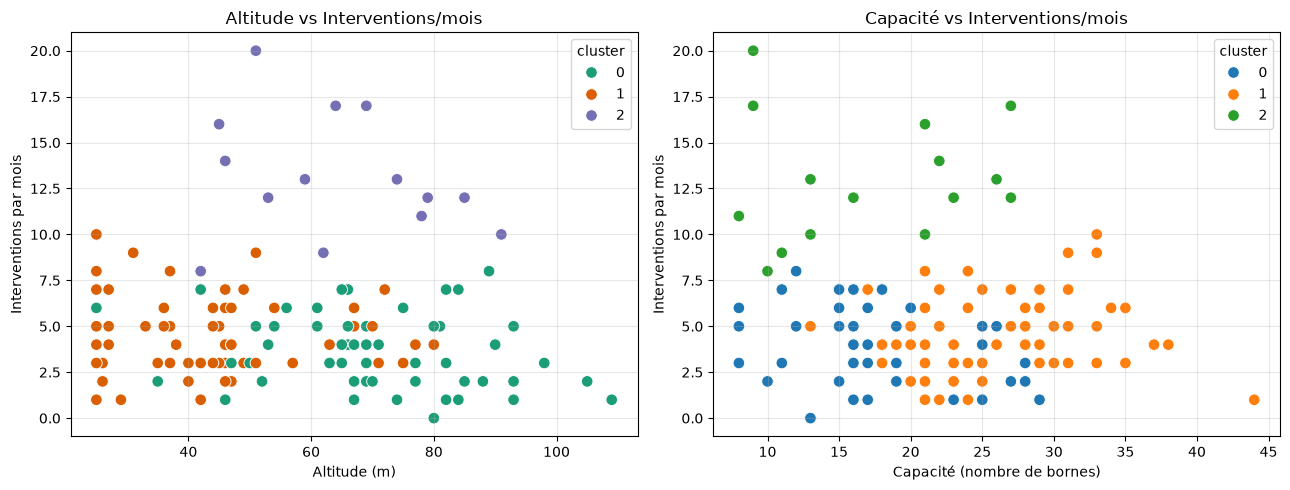

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns


fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Altitude vs Interventions/mois
sns.scatterplot(
    data=df_stations,
    x="altitude_m",
    y="interventions_mois",
    hue="cluster",
    palette="tab10",
    s=70,
    ax=axes[0],
)
axes[0].set_title("Altitude vs Interventions/mois")
axes[0].set_xlabel("Altitude (m)")
axes[0].set_ylabel("Interventions par mois")
axes[0].grid(True, alpha=0.3)

# 2. Capacité vs Interventions/mois
sns.scatterplot(
    data=df_stations,
    x="capacite",
    y="interventions_mois",
    hue="cluster",
    palette="tab10",
    s=70,
    ax=axes[1],
)
axes[1].set_title("Capacité vs Interventions/mois")
axes[1].set_xlabel("Capacité (nombre de bornes)")
axes[1].set_ylabel("Interventions par mois")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Déduction de la politique de rééquilibrage (Question 8)

In [12]:
# 1. Garder le même ordre de clusters que df_stations et df_profil
df_stations["cluster"] = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X)
df_profil["cluster"] = df_stations["cluster"].values

# 2. Ajouter les flux du matin et calculer le solde
stations = df_stations.merge(
    df_profil[["station", "dep_matin", "arr_matin"]],
    left_on="station_id",
    right_on="station",
    how="left",
).fillna({"dep_matin": 0, "arr_matin": 0})

stations["departs_matin"] = stations["dep_matin"]
stations["arrivees_matin"] = stations["arr_matin"]
stations["solde_matin"] = stations["arrivees_matin"] - stations["departs_matin"]

# 3. Associer des noms simples et des politiques claires
stations["type_station"] = stations["cluster"].map({
    0: "Stations en altitude",
    1: "Grandes stations en plaine",
    2: "Stations saturées (gares)",
})

stations["politique"] = stations["cluster"].map({
    0: "Intervention si alerte (hors heures de pointe)",
    1: "Suivi normal en journée",
    2: "Rééquilibrage prioritaire aux heures de pointe",
})

# 4. Afficher le tableau résumé
tableau = (
    stations.groupby(["cluster", "type_station", "politique"])
    .agg(
        nb_stations=("station_id", "count"),
        interventions_moy=("interventions_mois", "mean"),
        departs_matin=("departs_matin", "mean"),
        arrivees_matin=("arrivees_matin", "mean"),
        solde_matin=("solde_matin", "mean"),
    )
    .round(1)
)
display(tableau)

,,,nb_stations,interventions_moy,departs_matin,arrivees_matin,solde_matin
cluster,type_station,politique,,,,,
0,Stations en altitude,Intervention si alerte (hors heures de pointe),54,3.7,1.4,1.3,-0.1
1,Grandes stations en plaine,Suivi normal en journée,71,4.5,1.3,1.5,0.2
2,Stations saturées (gares),Rééquilibrage prioritaire aux heures de pointe,15,12.9,1.5,0.7,-0.7


**Solde = arrivées matin - départs matin**

* **Si le solde est négatif ($\text{solde} < 0$, départs $>$ arrivées) :** les stations se vident rapidement le matin.
 **Conséquence :** forte utilisation de vélos (risque de manque de vélos disponibles).
* **Si le solde est positif ($\text{solde} > 0$, départs $<$ arrivées) :** les stations se remplissent massivement le matin.
  **Conséquence :** saturation des bornes (plus de place pour raccrocher).
 * **Si le solde est égal à $0$ ou proche de $0$ :** soit les stations sont peu utilisées le matin, soit le nombre d'arrivées est équivalent au nombre de départs.

## Conclusion de l'analyse des stations (Clustering K-Means)

Cette analyse a permis de segmenter les **140 stations CityCycle** en **3 profils d'exploitation distincts** à partir de trois variables complémentaires et non redondantes : la **capacité** (`capacite`), le **dénivelé** (`altitude_m`) et la **charge d'interventions** (`interventions_mois`), préalablement standardisées (`StandardScaler`).

### Synthèse des 3 profils identifiés
- **Cluster 0 — Stations en hauteur à faible sollicitation (54 stations) :** situées en altitude moyenne élevée (**~70,8 m**), de capacité modérée (**~17,9 bornes**) et nécessitant peu d'interventions (**~3,7 / mois**). Elles demandent une maintenance légère mais subissent les contraintes liées au dénivelé.
- **Cluster 1 — Grandes stations de plaine (71 stations) :** implantées sur des zones plus basses (**~40,9 m**), dotées d'une forte capacité (**~25,9 bornes**) et d'un niveau d'interventions modéré (**~4,5 / mois**). Elles constituent le cœur stable et bien dimensionné du réseau.
- **Cluster 2 — Stations critiques / fortement sollicitées (15 stations) :** de capacité réduite (**~17,1 bornes**) mais soumises à une très forte pression opérationnelle (**~12,9 interventions / mois**, principalement près des gares). Ce petit groupe concentre l'essentiel des besoins de régulation terrain.